# 03 – Evento de saída, primeira saída e unidades de análise

Issue #6. Fixa as definições que todas as análises seguintes usam e responde P2: *quantos alunos têm evento de saída, de que tipo, e quantos voltam depois?*

As regras estão em `src/eventos.py`; este notebook aplica as funções e confere as contagens.

> Só contagens agregadas. Grupos com menos de 10 alunos aparecem como `<10` (`src/privacidade.py`). Nenhum `HANDLE*` aparece nas saídas.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from src.dados import carregar_base
from src.eventos import (
    CODIGO_ALUNO_ESPECIAL, FLAGS_SAIDA, consolidar_aluno_semestre, filtrar_graduacao,
    marcar_evento_saida, marcar_saida_semestre_seguinte, tabela_por_aluno,
)
from src.privacidade import ocultar_contagens_pequenas

# Desligamento é raríssimo na graduação: nas tabelas, ele aparece junto com o cancelamento,
# para que o número exato não possa ser obtido por subtração do total.
TIPO_EXIBICAO = {"Cancelamento": "Cancelamento ou desligamento", "Desligamento": "Cancelamento ou desligamento"}

FIGURAS = RAIZ / "reports" / "figures"
FIGURAS.mkdir(parents=True, exist_ok=True)

base = carregar_base()
print("Base carregada.")

Base carregada.


## 1. Recorte da graduação

A legenda descreve 12 códigos de curso, um deles de **aluno especial**, fora da graduação regular. Pela base, o código é o `GAE`: é onde se concentra o `PERIODO = 0`, que a legenda associa ao aluno especial, e nenhum aluno do `GAE` tem outro curso. A confirmação da sigla junto à fonte fica na issue #3.

**Decisão:** excluir o código de aluno especial de todas as análises, porque o tema é a graduação.

In [2]:
periodo_zero = (
    base.assign(grupo=base["SIGLACURSO"].eq(CODIGO_ALUNO_ESPECIAL).map({True: CODIGO_ALUNO_ESPECIAL, False: "Demais cursos"}))
    .groupby("grupo")
    .agg(alunos=("HANDLEALUNO", "nunique"), linhas_periodo_0=("PERIODO", lambda s: int((s == 0).sum())))
)
alunos_gae = set(base.loc[base["SIGLACURSO"] == CODIGO_ALUNO_ESPECIAL, "HANDLEALUNO"])
outro_curso = base.loc[base["HANDLEALUNO"].isin(alunos_gae) & (base["SIGLACURSO"] != CODIGO_ALUNO_ESPECIAL), "HANDLEALUNO"].nunique()

print(f"Alunos do {CODIGO_ALUNO_ESPECIAL} que também aparecem em outro curso: {outro_curso}")
ocultar_contagens_pequenas(periodo_zero)

Alunos do GAE que também aparecem em outro curso: 0


,alunos,linhas_periodo_0
grupo,,
Demais cursos,7.589,<10
GAE,26,24


In [3]:
df = filtrar_graduacao(base)

pd.DataFrame(
    {
        "Base completa": [len(base), base["HANDLEALUNO"].nunique()],
        "Graduação (sem aluno especial)": [len(df), df["HANDLEALUNO"].nunique()],
    },
    index=["Linhas", "Alunos"],
)

,Base completa,Graduação (sem aluno especial)
Linhas,59059,59032
Alunos,7615,7589


## 2. Evento de saída na linha

**Definição:** a linha tem evento de saída quando ao menos uma das flags `TEVEDESISTENCIA`, `TEVEABANDONO`, `TEVECANCELAMENTO` ou `TEVEDESLIGAMENTO` vale 1. São os mesmos quatro tipos que alimentam `DATAPRIMEIRASAIDA`, então as duas coisas devem coincidir.

**Não são evento de saída:** trancamento, transferência/afastamento, afastamento sem ocorrência, prazo esgotado, rematrícula, falecimento, mudança de curso, migração de currículo, diplomação e reingresso.

In [4]:
df = marcar_evento_saida(df)

conferencia = pd.crosstab(
    df["EVENTO_SAIDA_LINHA"].map({0: "Sem evento", 1: "Com evento"}),
    df["DATAPRIMEIRASAIDA"].notna().map({False: "DATAPRIMEIRASAIDA vazia", True: "DATAPRIMEIRASAIDA preenchida"}),
)
conferencia.index.name = conferencia.columns.name = None
print("Linhas com mais de um tipo de saída:", int((df[list(FLAGS_SAIDA)].sum(axis=1) > 1).sum()))
conferencia

Linhas com mais de um tipo de saída: 0


,DATAPRIMEIRASAIDA preenchida,DATAPRIMEIRASAIDA vazia
Com evento,3838,0
Sem evento,0,55194


In [5]:
linhas_evento = df.loc[df["EVENTO_SAIDA_LINHA"] == 1]
tipos_linha = pd.crosstab(
    linhas_evento["TIPO_SAIDA"].replace(TIPO_EXIBICAO), linhas_evento["ORIGEMREGISTRO"], margins=True, margins_name="Total"
)
tipos_linha.index.name = "Tipo de saída"
tipos_linha.columns.name = "Origem da linha"
print("Linhas com evento de saída, por tipo e origem:")
ocultar_contagens_pequenas(tipos_linha)

Linhas com evento de saída, por tipo e origem:


Origem da linha,ACADEMICA,OCORRENCIA,Total
Tipo de saída,,,
Abandono,0,760,760
Cancelamento ou desligamento,316,451,767
Desistência,1.171,1.140,2.311
Total,1.487,2.351,3.838


## 3. Visão aluno-semestre

O mesmo aluno pode ter mais de uma linha no mesmo semestre, quando troca de curso ou migra de currículo: em geral uma linha `ACADEMICA` do vínculo novo e uma `OCORRENCIA` do antigo. `consolidar_aluno_semestre()` deixa uma linha por aluno e semestre:

- **curso, turno, período e indicadores** vêm de uma só linha, a *linha principal*: a `ACADEMICA`; entre duas `ACADEMICA`, a do vínculo de ingresso mais recente; persistindo o empate, a com mais disciplinas matriculadas;
- **flags `TEVE*`** valem 1 se alguma linha do semestre tem a ocorrência; **datas** ficam com a menor data;
- `TEM_ACADEMICA` diz se o aluno cursou o semestre.

In [6]:
aluno_semestre = consolidar_aluno_semestre(df)

def classificar_semestre(origens):
    n_acad = int((origens == "ACADEMICA").sum())
    n_ocor = len(origens) - n_acad
    if n_acad > 1:
        return "Duas linhas ACADEMICA (com ou sem OCORRENCIA)"
    if n_acad == 1:
        return "Uma ACADEMICA" if n_ocor == 0 else "Uma ACADEMICA + OCORRENCIA(s)"
    return "Uma OCORRENCIA" if n_ocor == 1 else "Duas ou mais OCORRENCIA"

ordem = ["Uma ACADEMICA", "Uma ACADEMICA + OCORRENCIA(s)", "Duas linhas ACADEMICA (com ou sem OCORRENCIA)",
         "Uma OCORRENCIA", "Duas ou mais OCORRENCIA"]
origens = (
    df.groupby(["HANDLEALUNO", "ANOSEMESTRE_ORD"])["ORIGEMREGISTRO"]
    .agg(classificar_semestre)
    .value_counts()
    .reindex(ordem)
    .rename("aluno-semestres")
)
origens.index.name = "Linhas da base no semestre"
print(f"Linhas da base (graduação): {len(df):,}".replace(",", "."))
print(f"Aluno-semestres: {len(aluno_semestre):,}".replace(",", "."))
ocultar_contagens_pequenas(origens).to_frame()

Linhas da base (graduação): 59.032
Aluno-semestres: 48.173


,aluno-semestres
Linhas da base no semestre,
Uma ACADEMICA,36.117
Uma ACADEMICA + OCORRENCIA(s),8.182
Duas linhas ACADEMICA (com ou sem OCORRENCIA),47
Uma OCORRENCIA,3.231
Duas ou mais OCORRENCIA,596


## 4. Saídas que são trocas de curso ou de currículo

Quando o aluno troca de curso ou migra de currículo, o vínculo antigo pode receber um registro de saída (por exemplo, um cancelamento) no mesmo semestre em que ele continua estudando no vínculo novo. Contar isso como saída contradiria a própria definição, que diz que mudança de curso e migração não são evento de saída.

Mas um registro de troca no semestre não garante que o aluno continuou: ele pode ter feito a troca e saído em seguida. Por isso a regra pede duas condições juntas.

**Regra:** o evento do semestre é uma **saída por troca** (e não conta) quando:
1. **há troca no semestre:** mudança de curso ou migração de currículo registrada, **ou** linha `ACADEMICA` em outro vínculo que não o do evento; **e**
2. **há continuidade:** o aluno cursa (linha `ACADEMICA`) algum semestre posterior.

Se há troca, mas o aluno não cursa mais nenhum semestre, o evento **conta como saída**. No último semestre da base a continuidade não pode ser observada; ali vale só a primeira condição.

In [7]:
com_evento = aluno_semestre["EVENTO_SAIDA_BRUTO"] == 1
com_troca = com_evento & (aluno_semestre["TROCA_NO_SEMESTRE"] == 1)
por_troca = aluno_semestre["SAIDA_POR_TROCA"] == 1
ultimo_semestre = aluno_semestre["ANOSEMESTRE_ORD"].max()
no_ultimo = aluno_semestre["ANOSEMESTRE_ORD"] == ultimo_semestre

# Entre as saídas por troca, quantas têm reingresso em semestre posterior
# (possível saída de verdade seguida de volta, que a regra não separa).
ultimo_reingresso = (
    aluno_semestre.loc[aluno_semestre["TEVEREINGRESSO"] == 1].groupby("HANDLEALUNO")["ANOSEMESTRE_ORD"].max()
)
reingresso_depois = aluno_semestre["HANDLEALUNO"].map(ultimo_reingresso) > aluno_semestre["ANOSEMESTRE_ORD"]

trocas = pd.Series(
    {
        "Aluno-semestres com alguma linha de saída": int(com_evento.sum()),
        "  … com troca no semestre": int(com_troca.sum()),
        "      … e o aluno cursa depois (saída por troca, não conta)": int((por_troca & ~no_ultimo).sum()),
        "      … no último semestre da base (saída por troca, continuidade assumida)": int((por_troca & no_ultimo).sum()),
        "      … e o aluno não cursa mais nenhum semestre (conta como saída)": int((com_troca & ~por_troca).sum()),
        "Saídas por troca com reingresso em semestre posterior": int((por_troca & reingresso_depois).sum()),
        "Aluno-semestres com evento de saída": int(aluno_semestre["EVENTO_SAIDA"].sum()),
    },
    name="aluno-semestres",
)
ocultar_contagens_pequenas(trocas).to_frame()

,aluno-semestres
Aluno-semestres com alguma linha de saída,3.725
… com troca no semestre,233
"… e o aluno cursa depois (saída por troca, não conta)",79
"… no último semestre da base (saída por troca, continuidade assumida)",31
… e o aluno não cursa mais nenhum semestre (conta como saída),123
Saídas por troca com reingresso em semestre posterior,<10
Aluno-semestres com evento de saída,3.615


## 5. Primeira saída por aluno (P2)

**Primeira saída:** o primeiro semestre do aluno com evento de saída. A tabela por aluno (`tabela_por_aluno()`) guarda curso, turno e ingresso do **primeiro** semestre do aluno, porque esses atributos mudam ao longo da base para parte dos alunos.

In [8]:
aluno_semestre = marcar_saida_semestre_seguinte(aluno_semestre)
alunos = tabela_por_aluno(aluno_semestre)

n_alunos = len(alunos)
n_saida = int(alunos["TEVE_SAIDA"].sum())
resumo = pd.DataFrame(
    {
        "alunos": [
            n_alunos,
            n_saida,
            int((alunos["N_SEMESTRES_SAIDA"] > 1).sum()),
        ]
    },
    index=["Alunos (graduação)", "Com pelo menos uma saída", "Com mais de um semestre de saída"],
)
resumo["% dos alunos"] = (resumo["alunos"] / n_alunos * 100).round(1)
resumo["alunos"] = ocultar_contagens_pequenas(resumo["alunos"])
resumo

,alunos,% dos alunos
Alunos (graduação),7.589,100.0
Com pelo menos uma saída,3.425,45.1
Com mais de um semestre de saída,176,2.3


In [9]:
tipos = alunos["TIPO_PRIMEIRA_SAIDA"].replace(TIPO_EXIBICAO).value_counts().rename("alunos").to_frame()
tipos["% das primeiras saídas"] = (tipos["alunos"] / n_saida * 100).round(1)
tipos["alunos"] = ocultar_contagens_pequenas(tipos["alunos"])
tipos.index.name = "Tipo da primeira saída"
tipos

,alunos,% das primeiras saídas
Tipo da primeira saída,,
Desistência,2.107,61.5
Cancelamento ou desligamento,709,20.7
Abandono,609,17.8


## 6. O que acontece depois da primeira saída

Se uma parte dos alunos volta a estudar depois da primeira saída, o evento de saída não pode ser chamado de evasão definitiva. Contamos, entre os alunos com saída, quantos têm em **algum semestre posterior**: matrícula efetivada (linha `ACADEMICA`, em qualquer curso), reingresso ou diplomação.

In [10]:
com_saida = alunos.loc[alunos["TEVE_SAIDA"] == 1]
depois = pd.DataFrame(
    {
        "alunos": [
            int(com_saida["CURSOU_DEPOIS"].sum()),
            int(com_saida["REINGRESSO_DEPOIS"].sum()),
            int(com_saida["DIPLOMACAO_DEPOIS"].sum()),
        ]
    },
    index=[
        "Voltaram a cursar (matrícula efetivada depois)",
        "Tiveram reingresso depois",
        "Diplomaram-se depois",
    ],
)
depois["% dos alunos com saída"] = (depois["alunos"] / n_saida * 100).round(1)
depois["alunos"] = ocultar_contagens_pequenas(depois["alunos"])
depois

,alunos,% dos alunos com saída
Voltaram a cursar (matrícula efetivada depois),332,9.7
Tiveram reingresso depois,136,4.0
Diplomaram-se depois,103,3.0


## 7. Primeira saída ao longo do tempo

**Cuidado ao ler:** a base é formada por turmas de ingresso a partir de 2009/1. De 2009 a 2013 ela só tem alunos dos primeiros períodos, então o número de saídas nesses anos mistura o efeito do tempo com o crescimento da base. Os últimos semestres também têm menos tempo de acompanhamento.

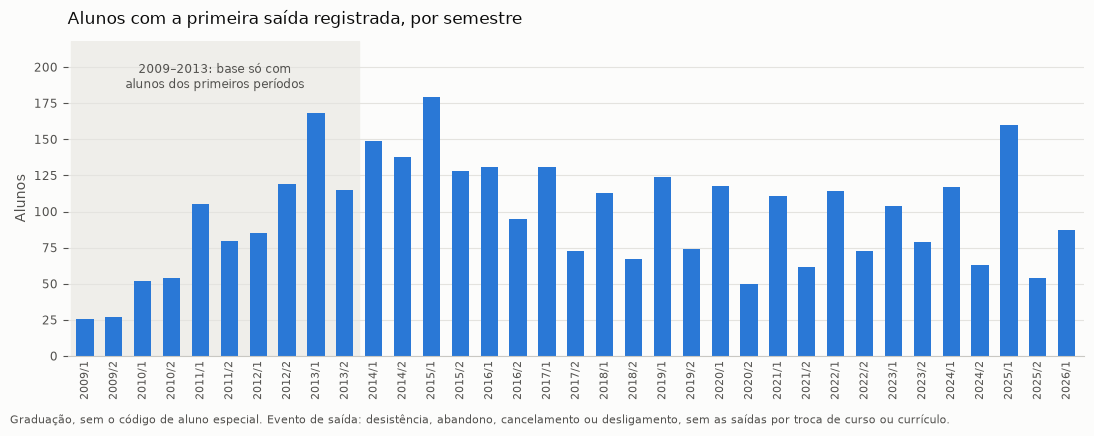

In [11]:
por_semestre = (
    alunos.dropna(subset=["PRIMEIRA_SAIDA_ORD"])
    .groupby(["PRIMEIRA_SAIDA_ORD", "PRIMEIRA_SAIDA"])
    .size()
    .rename("alunos")
    .reset_index()
    .sort_values("PRIMEIRA_SAIDA_ORD")
)
assert (por_semestre["alunos"] >= 10).all(), "Há semestre com menos de 10 alunos: agrupar antes de publicar."

AZUL, TEXTO, TEXTO_2, GRADE, FUNDO = "#2a78d6", "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"

fig, ax = plt.subplots(figsize=(11, 4.2), facecolor=FUNDO)
ax.set_facecolor(FUNDO)
x = range(len(por_semestre))
inicio_2014 = por_semestre["PRIMEIRA_SAIDA"].str[:4].astype(int).lt(2014).sum()
ax.axvspan(-0.5, inicio_2014 - 0.5, color="#efeeea", zorder=0)
ax.text(
    (inicio_2014 - 1) / 2, por_semestre["alunos"].max() * 1.02,
    "2009–2013: base só com\nalunos dos primeiros períodos", ha="center", va="bottom", fontsize=8.5, color=TEXTO_2,
)
ax.bar(x, por_semestre["alunos"], width=0.6, color=AZUL, zorder=2)
ax.set_xticks(list(x))
ax.set_xticklabels(por_semestre["PRIMEIRA_SAIDA"], rotation=90, fontsize=8, color=TEXTO_2)
ax.set_xlim(-0.6, len(por_semestre) - 0.4)
ax.set_ylim(0, por_semestre["alunos"].max() * 1.22)
ax.set_ylabel("Alunos", color=TEXTO_2)
ax.tick_params(axis="y", colors=TEXTO_2, labelsize=8.5)
ax.tick_params(axis="x", length=0)
ax.grid(axis="y", color=GRADE, linewidth=0.8, zorder=1)
for lado in ["top", "right", "left"]:
    ax.spines[lado].set_visible(False)
ax.spines["bottom"].set_color("#c9c8c3")
ax.set_title(
    "Alunos com a primeira saída registrada, por semestre", loc="left", fontsize=12, color=TEXTO, pad=12,
)
fig.text(0.01, -0.02, "Graduação, sem o código de aluno especial. Evento de saída: desistência, abandono, cancelamento ou desligamento, sem as saídas por troca de curso ou currículo.",
         fontsize=8, color=TEXTO_2)
fig.tight_layout()
fig.savefig(FIGURAS / "03_primeira_saida_por_semestre.png", dpi=150, bbox_inches="tight", facecolor=FUNDO)
plt.show()

In [12]:
# Tabela com os mesmos números do gráfico.
por_semestre.set_index("PRIMEIRA_SAIDA")[["alunos"]].T

PRIMEIRA_SAIDA,2009/1,2009/2,2010/1,2010/2,2011/1,2011/2,2012/1,2012/2,2013/1,2013/2,...,2021/2,2022/1,2022/2,2023/1,2023/2,2024/1,2024/2,2025/1,2025/2,2026/1
alunos,26,27,52,54,105,80,85,119,168,115,...,62,114,73,104,79,117,63,160,54,87


## 8. Rótulo para a modelagem

`marcar_saida_semestre_seguinte()` cria `SAIDA_SEMESTRE_SEGUINTE`: **1** se a primeira saída do aluno acontece no semestre calendário seguinte, **0** se não. O rótulo fica **vazio**, e a linha sai da modelagem (issue #12), em dois casos:

- nos semestres da primeira saída em diante;
- no **último semestre da base**, porque o semestre seguinte não foi observado: não dá para saber se houve saída.

A issue #12 também decide se usa só os semestres cursados (`TEM_ACADEMICA = 1`).

In [13]:
antes = aluno_semestre.loc[aluno_semestre["ANTES_PRIMEIRA_SAIDA"] == 1]
rotulados = antes.loc[antes["SAIDA_SEMESTRE_SEGUINTE"].notna()]
sem_rotulo_ultimo = int((antes["ANOSEMESTRE_ORD"] == ultimo_semestre).sum())
rotulo = pd.crosstab(
    rotulados["TEM_ACADEMICA"].map({1: "Semestre cursado (ACADEMICA)", 0: "Semestre não cursado"}),
    rotulados["SAIDA_SEMESTRE_SEGUINTE"].map({1: "Saída no semestre seguinte", 0: "Sem saída no semestre seguinte"}),
    margins=True, margins_name="Total",
)
rotulo.index.name = rotulo.columns.name = None
positivos = rotulados["SAIDA_SEMESTRE_SEGUINTE"].astype(float).mean() * 100
ultimo_nome = aluno_semestre.loc[no_ultimo, "ANOSEMESTRE"].iloc[0]
print(f"Semestres sem rótulo por serem o último da base ({ultimo_nome}): {sem_rotulo_ultimo:,}".replace(",", "."))
print(f"Proporção de positivos entre os semestres com rótulo: {positivos:.1f}%")
ocultar_contagens_pequenas(rotulo)

Semestres sem rótulo por serem o último da base (2026/1): 1.408
Proporção de positivos entre os semestres com rótulo: 4.5%


,Saída no semestre seguinte,Sem saída no semestre seguinte,Total
Semestre cursado (ACADEMICA),1.452,38.457,39.909
Semestre não cursado,405,951,1.356
Total,1.857,39.408,41.265


### Premissa: sem registro de saída, sem saída

Dentro do período da base, um semestre recebe rótulo **0** quando não há registro de saída no semestre seguinte. Isso supõe que a falta de registro quer dizer que o aluno não saiu. Para conferir, a tabela abaixo olha os semestres com rótulo 0 em que o aluno **não tem nenhuma linha** no semestre seguinte e mostra o que acontece com ele.

In [14]:
chaves = set(zip(aluno_semestre["HANDLEALUNO"], aluno_semestre["ANOSEMESTRE_ORD"]))
negativos = rotulados.loc[rotulados["SAIDA_SEMESTRE_SEGUINTE"] == 0]
sem_seguinte = negativos.loc[
    [(aluno, semestre + 1) not in chaves for aluno, semestre in zip(negativos["HANDLEALUNO"], negativos["ANOSEMESTRE_ORD"])]
]
ultimo_do_aluno = aluno_semestre.groupby("HANDLEALUNO")["ANOSEMESTRE_ORD"].max()
volta = sem_seguinte["ANOSEMESTRE_ORD"] < sem_seguinte["HANDLEALUNO"].map(ultimo_do_aluno)
diplomou = ~volta & (sem_seguinte["TEVEDIPLOMACAO"] == 1)
transferencia = ~volta & ~diplomou & (sem_seguinte["TEVETRANSAFASTAMENTO"] == 1)
outros = ~volta & ~diplomou & ~transferencia

premissa = pd.DataFrame(
    {
        "aluno-semestres": [
            int(diplomou.sum()), int(volta.sum()), int(transferencia.sum()), int(outros.sum()), len(sem_seguinte),
        ]
    },
    index=[
        "Diplomou-se no semestre",
        "Some e volta a aparecer depois",
        "Transferência ou afastamento, sem volta",
        "Outros (falecimento ou nenhum registro)",
        "Total sem linha no semestre seguinte",
    ],
)
premissa["% do total"] = (premissa["aluno-semestres"] / len(sem_seguinte) * 100).round(1)
premissa["aluno-semestres"] = ocultar_contagens_pequenas(premissa["aluno-semestres"])
print(f"Semestres com rótulo 0: {len(negativos):,}".replace(",", "."))
premissa

Semestres com rótulo 0: 39.408


,aluno-semestres,% do total
Diplomou-se no semestre,2.455,83.1
Some e volta a aparecer depois,199,6.7
"Transferência ou afastamento, sem volta",279,9.4
Outros (falecimento ou nenhum registro),22,0.7
Total sem linha no semestre seguinte,2.955,100.0


Quase todos os casos têm explicação nos próprios registros: diplomação, volta posterior ou transferência/afastamento, que pela definição não é evento de saída. Os que somem sem nenhum registro são poucos, então a premissa é razoável. A transferência ou afastamento sem volta fica como **decisão consciente**: não conta como saída porque a base não diz se o aluno foi para outra instituição ou só se afastou.

### Alunos sem um semestre positivo

Um aluno só gera um exemplo positivo se tem, na base, o semestre imediatamente anterior à primeira saída. Quem tem a primeira saída já no primeiro semestre em que aparece na base não contribui com positivo (há também menos de 10 alunos com um intervalo sem registro antes da saída, contados juntos). Isso afeta as issues #9 (semestre anterior à saída) e #12 (modelagem): esses alunos ficam fora das duas análises e precisam ser citados como limitação.

In [15]:
com_positivo = set(antes.loc[antes["SAIDA_SEMESTRE_SEGUINTE"] == 1, "HANDLEALUNO"])
com_saida_idx = alunos.index[alunos["TEVE_SAIDA"] == 1]
sem_positivo = alunos.loc[[a for a in com_saida_idx if a not in com_positivo]]
saiu_no_primeiro = sem_positivo["PRIMEIRA_SAIDA_ORD"] == sem_positivo["PRIMEIRO_SEMESTRE_ORD"]

# Quase todos os que não geram positivo têm a primeira saída no primeiro semestre em que aparecem.
# Os demais (intervalo sem registro antes da saída) são menos de 10 e não aparecem separados.
assert saiu_no_primeiro.mean() > 0.99

sem_positivo_tab = pd.DataFrame(
    {"alunos": [len(com_positivo), len(sem_positivo)]},
    index=[
        "Têm o semestre anterior à primeira saída (geram positivo)",
        "Não têm: saída no primeiro semestre em que aparecem na base",
    ],
)
sem_positivo_tab["% dos alunos com saída"] = (sem_positivo_tab["alunos"] / n_saida * 100).round(1)
sem_positivo_tab["alunos"] = ocultar_contagens_pequenas(sem_positivo_tab["alunos"])
sem_positivo_tab

,alunos,% dos alunos com saída
Têm o semestre anterior à primeira saída (geram positivo),1.857,54.2
Não têm: saída no primeiro semestre em que aparecem na base,1.568,45.8


## Definições fixadas (usadas em todas as issues seguintes)

| Termo | Definição |
|---|---|
| Recorte | Graduação: exclui o código de aluno especial (`GAE`) |
| Evento de saída | Semestre com desistência, abandono, cancelamento ou desligamento em alguma linha do aluno, **exceto** saída por troca |
| Saída por troca | Saída registrada no mesmo semestre de uma mudança de curso, de uma migração de currículo ou de matrícula efetivada em outro vínculo, **desde que** o aluno curse algum semestre depois (no último semestre da base, a continuidade é assumida) |
| Primeira saída | Primeiro semestre do aluno com evento de saída |
| Visão aluno | Uma linha por aluno, com curso, turno e ingresso do primeiro semestre (issue #8) |
| Visão aluno-semestre | Uma linha por aluno e semestre, com a linha principal para os indicadores (issues #9 a #12) |
| Rótulo da modelagem | `SAIDA_SEMESTRE_SEGUINTE`: primeira saída no semestre seguinte (issue #12); vazio no último semestre da base |
| Premissa do rótulo | Sem registro de saída no semestre seguinte = não houve saída (seção 8) |

Evento de saída **não** é evasão definitiva: parte dos alunos volta a estudar depois (seção 6).